In [143]:
import pandas as pd

dataset = '/home/mayank/Desktop/sabudh/Python/Dataset/archive/Sport car price.csv'

data = pd.read_csv(dataset)
dataset = pd.DataFrame(data)

print(dataset.head(5))


      Car Make Car Model  Year Engine Size (L) Horsepower Torque (lb-ft)  \
0      Porsche       911  2022               3        379            331   
1  Lamborghini   Huracan  2021             5.2        630            443   
2      Ferrari   488 GTB  2022             3.9        661            561   
3         Audi        R8  2022             5.2        562            406   
4      McLaren      720S  2021               4        710            568   

  0-60 MPH Time (seconds) Price (in USD)  
0                       4        101,200  
1                     2.8        274,390  
2                       3        333,750  
3                     3.2        142,700  
4                     2.7        298,000  


# Question text
## Dataset: https://www.kaggle.com/datasets/rkiattisak/sports-car-prices-dataset
#
## 1. Load the dataset into a Pandas DataFrame and display the first 5 rows to get an idea of the data.
## 2. Use Pandas to clean the dataset by removing any missing or duplicate values, and converting any non-numeric data to numeric data where appropriate.
## 3. Use Pandas to explore the dataset by computing summary statistics for each column, such as mean, median, mode, standard deviation, and range (Range should be calculated as (max − min))
## 4. Use Pandas to group the dataset by car make and compute the average price for each make.
## 5. Use Pandas to group the dataset by year and compute the average horsepower for each year.
## 6. Use Pandas to create a scatter plot of price versus horsepower, and add a linear regression line to the plot (Use NumPy polyfit() to add a regression line.)
## 7. Use Pandas to create a histogram of the 0-60 MPH times in the dataset, with bins of size 0.5 seconds.
## 8. Use Pandas to filter the dataset to only include cars with a price greater than $500,000, and then sort the resulting dataset by horsepower in descending order.
## 9. Use Pandas to export the cleaned and transformed dataset to a new CSV file


In [144]:
b = len(dataset)
dataset = dataset.drop_duplicates()
print(f"Removed {b-len(dataset)} duplicated rows")

Removed 288 duplicated rows


In [145]:
c = len(dataset)
df = dataset.dropna()
print(f" Missing values: {c - len(df)} ")


 Missing values: 12 


In [146]:
df.info()


<class 'pandas.DataFrame'>
Index: 707 entries, 0 to 1006
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Car Make                 707 non-null    str  
 1   Car Model                707 non-null    str  
 2   Year                     707 non-null    int64
 3   Engine Size (L)          707 non-null    str  
 4   Horsepower               707 non-null    str  
 5   Torque (lb-ft)           707 non-null    str  
 6   0-60 MPH Time (seconds)  707 non-null    str  
 7   Price (in USD)           707 non-null    str  
dtypes: int64(1), str(7)
memory usage: 74.2 KB


In [147]:
df.head(10)

,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
0,Porsche,911,2022,3,379,331,4,"101,200"
1,Lamborghini,Huracan,2021,5.2,630,443,2.8,"274,390"
2,Ferrari,488 GTB,2022,3.9,661,561,3,"333,750"
3,Audi,R8,2022,5.2,562,406,3.2,"142,700"
4,McLaren,720S,2021,4,710,568,2.7,"298,000"
5,BMW,M8,2022,4.4,617,553,3.1,"130,000"
6,Mercedes-Benz,AMG GT,2021,4,523,494,3.8,"118,500"
7,Chevrolet,Corvette,2021,6.2,490,465,2.8,"59,900"
8,Ford,Mustang Shelby GT500,2022,5.2,760,625,3.5,"81,000"
9,Nissan,GT-R Nismo,2021,3.8,600,481,2.5,"212,000"


In [149]:
neumeric_cols= ["Engine Size (L)","Torque (lb-ft)","0-60 MPH Time (seconds)","Horsepower"]

for col in neumeric_cols:
    print(col,"is: ",df[col].dtype)

    df[col] = pd.to_numeric(df[col], errors ='coerce')
    print(f"\n{col} is changed to neumeric")


df['Price (in USD)'] = (
    df['Price (in USD)']
    .astype(str)
    .str.replace('[$,]', '', regex=True)
    .astype(float)
)  
leng = len(df)
df = df.dropna()
print("Removed null Rows",leng-len(df))    

Engine Size (L) is:  float64

Engine Size (L) is changed to neumeric
Torque (lb-ft) is:  float64

Torque (lb-ft) is changed to neumeric
0-60 MPH Time (seconds) is:  float64

0-60 MPH Time (seconds) is changed to neumeric
Horsepower is:  float64

Horsepower is changed to neumeric
Removed null Rows 0


In [150]:
df.head()

,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
0,Porsche,911,2022,3.0,379.0,331.0,4.0,101200.0
1,Lamborghini,Huracan,2021,5.2,630.0,443.0,2.8,274390.0
2,Ferrari,488 GTB,2022,3.9,661.0,561.0,3.0,333750.0
3,Audi,R8,2022,5.2,562.0,406.0,3.2,142700.0
4,McLaren,720S,2021,4.0,710.0,568.0,2.7,298000.0


In [151]:
for col in neumeric_cols:
    print(col,"is: ",df[col].dtype)


Engine Size (L) is:  float64
Torque (lb-ft) is:  float64
0-60 MPH Time (seconds) is:  float64
Horsepower is:  float64


In [152]:
df.info()

<class 'pandas.DataFrame'>
Index: 663 entries, 0 to 1005
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Car Make                 663 non-null    str    
 1   Car Model                663 non-null    str    
 2   Year                     663 non-null    int64  
 3   Engine Size (L)          663 non-null    float64
 4   Horsepower               663 non-null    float64
 5   Torque (lb-ft)           663 non-null    float64
 6   0-60 MPH Time (seconds)  663 non-null    float64
 7   Price (in USD)           663 non-null    float64
dtypes: float64(5), int64(1), str(2)
memory usage: 57.4 KB


In [153]:
df.head()

,Car Make,Car Model,Year,Engine Size (L),Horsepower,Torque (lb-ft),0-60 MPH Time (seconds),Price (in USD)
0,Porsche,911,2022,3.0,379.0,331.0,4.0,101200.0
1,Lamborghini,Huracan,2021,5.2,630.0,443.0,2.8,274390.0
2,Ferrari,488 GTB,2022,3.9,661.0,561.0,3.0,333750.0
3,Audi,R8,2022,5.2,562.0,406.0,3.2,142700.0
4,McLaren,720S,2021,4.0,710.0,568.0,2.7,298000.0


### Use Pandas to explore the dataset by computing summary statistics for each column, such as mean, median, mode, standard deviation, and range (Range should be calculated as (max − min))

In [154]:
numeric_df = df.select_dtypes(include=[np.number])

summary_stats = {
    "Mean":numeric_df.mean(),
    "Median":numeric_df.median(),
    "Mode":numeric_df.mode(),
    "Standard Deviation":numeric_df.std(),
    "Min":numeric_df.min(),
    "Max":numeric_df.max(),
    "Range":numeric_df.max() - numeric_df.min()
}


 # Use Pandas to group the dataset by car make and compute the average price for each make.

In [155]:
avg_price_make = df.groupby('Car Make')['Price (in USD)'].mean().sort_values(ascending=False)
avg_price_make = avg_price_make.round(2)


In [157]:
avg_hp_year = df.groupby('Year')['Horsepower'].mean().sort_index()
avg_hp_year = avg_hp_year.round(2)

 # Use Pandas to create a scatter plot of price versus horsepower, and add a linear regression line to the plot (Use NumPy polyfit() to add a regression line.)

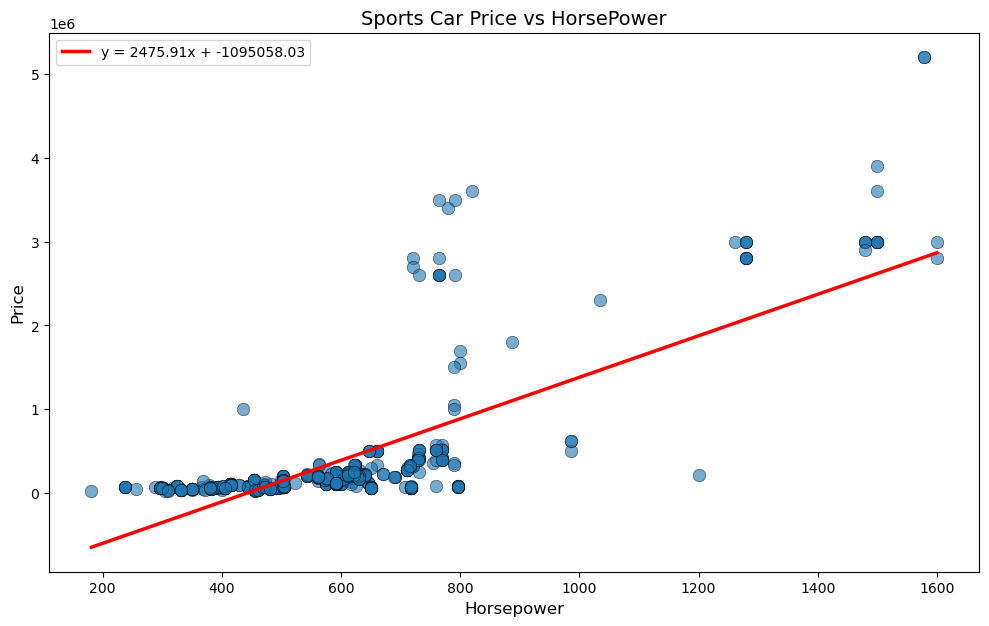

In [166]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,7))
plt.scatter(df["Horsepower"],df['Price (in USD)'], 
           alpha=0.6, edgecolors='k',linewidths=0.5,s=80)
slope, intercept = np.polyfit(df['Horsepower'],df['Price (in USD)'],1)

x_line = np.linspace(df['Horsepower'].min(),df["Horsepower"].max(),100)
y_line = slope * x_line + intercept
plt.plot(x_line,y_line, "r-",linewidth=2.5,
        label=f"y = {slope:.2f}x + {intercept:.2f}")

plt.xlabel("Horsepower",fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.title('Sports Car Price vs HorsePower', fontsize = 14)
plt.legend()
